# PRCP-1001 — Rice Leaf Disease Detection

# 1. Business Case

**Problem Statement**

This notebook covers the complete capstone project:
1. Complete data analysis report on the rice leaf disease image dataset
2. A model to classify three rice leaf diseases: **Leaf smut**, **Brown spot**, and **Bacterial leaf blight**
3. Analysis of data augmentation and other techniques used, with reasoning
4. Model comparison report — performance of multiple models and a production recommendation
5. Challenges-faced report

**Dataset:** 119–120 JPG images of disease-infected rice leaves, grouped into 3 classes (~40 images/class).

---


### 1.1 Importing Required Libraries

In [1]:

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                              confusion_matrix, classification_report)

from skimage.feature import graycomatrix, graycoprops, hog

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)


TensorFlow version: 2.21.0
GPU available: False


# 2. Data Loading

The dataset is organized as one folder per class:
```
data/
    Bacterial leaf blight/
    Brown spot/
    Leaf smut/
```

We use `tf.keras.utils.image_dataset_from_directory` purely to discover the class names and file paths — this replaces any manual `os.listdir`/`glob` file scanning.


In [2]:
from pathlib import Path

DATA_DIR = Path('data')
IMG_SIZE = 224

# Used only for its class-name/file-path discovery; batch_size=1 and shuffle=False
# keep the file order predictable for building our own dataframe below.
discovery_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=1, shuffle=False
)
CLASSES = discovery_ds.class_names
file_paths = discovery_ds.file_paths
print("Classes found:", CLASSES)
print("Total images found:", len(file_paths))


Found 119 files belonging to 3 classes.
Classes found: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
Total images found: 119


In [3]:

# Build a working dataframe of filepath + label. Labels are recovered from each
# path's parent folder name using plain string ops (no os.path needed).

CLASSES = sorted([f.name for f in DATA_DIR.iterdir() if f.is_dir()])

records = []

for cls in CLASSES:
    cls_dir = DATA_DIR/ cls
    for fname in cls_dir.iterdir():
        if fname.suffix.lower() in (".jpg", ".jpeg", ".png"):
            records.append({
                "filepath" : str(fname),
                "label" : cls,
                "filename" : fname.name
            })

        
df = pd.DataFrame(records)
df.head()


,filepath,label,filename
0,data\Bacterial leaf blight\DSC_0365.JPG,Bacterial leaf blight,DSC_0365.JPG
1,data\Bacterial leaf blight\DSC_0366.jpg,Bacterial leaf blight,DSC_0366.jpg
2,data\Bacterial leaf blight\DSC_0367.JPG,Bacterial leaf blight,DSC_0367.JPG
3,data\Bacterial leaf blight\DSC_0370.jpg,Bacterial leaf blight,DSC_0370.jpg
4,data\Bacterial leaf blight\DSC_0372.JPG,Bacterial leaf blight,DSC_0372.JPG


## 3. Exploratory Data Analysis (Task 1)

### 3.1 Class Distribution

label
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64


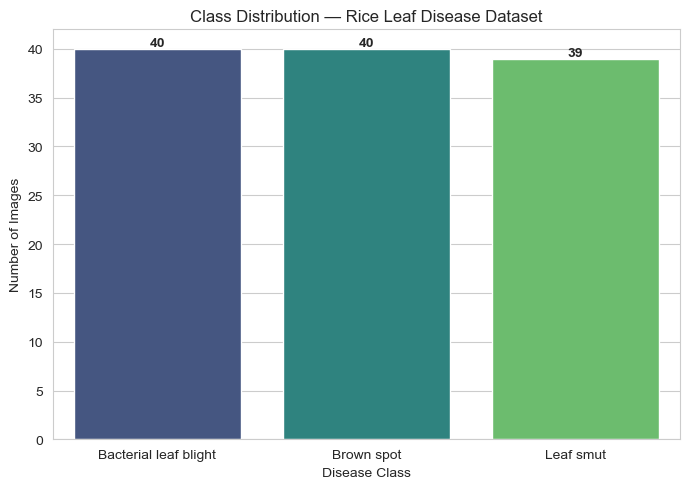

In [4]:

class_counts = df['label'].value_counts()
print(class_counts)

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Class Distribution — Rice Leaf Disease Dataset')
plt.ylabel('Number of Images')
plt.xlabel('Disease Class')
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 0.3, str(v), ha='center', fontweight='bold')
plt.tight_layout()
Path("outputs_figs").mkdir(parents=True, exist_ok=True)
plt.savefig('outputs_figs/class_distribution.png', dpi=100)
plt.show()


The dataset is (near-)balanced across the three classes, so accuracy is a reasonable primary metric, but we will still track macro F1 given the very small sample size.

### 3.2 Sample Images per Class

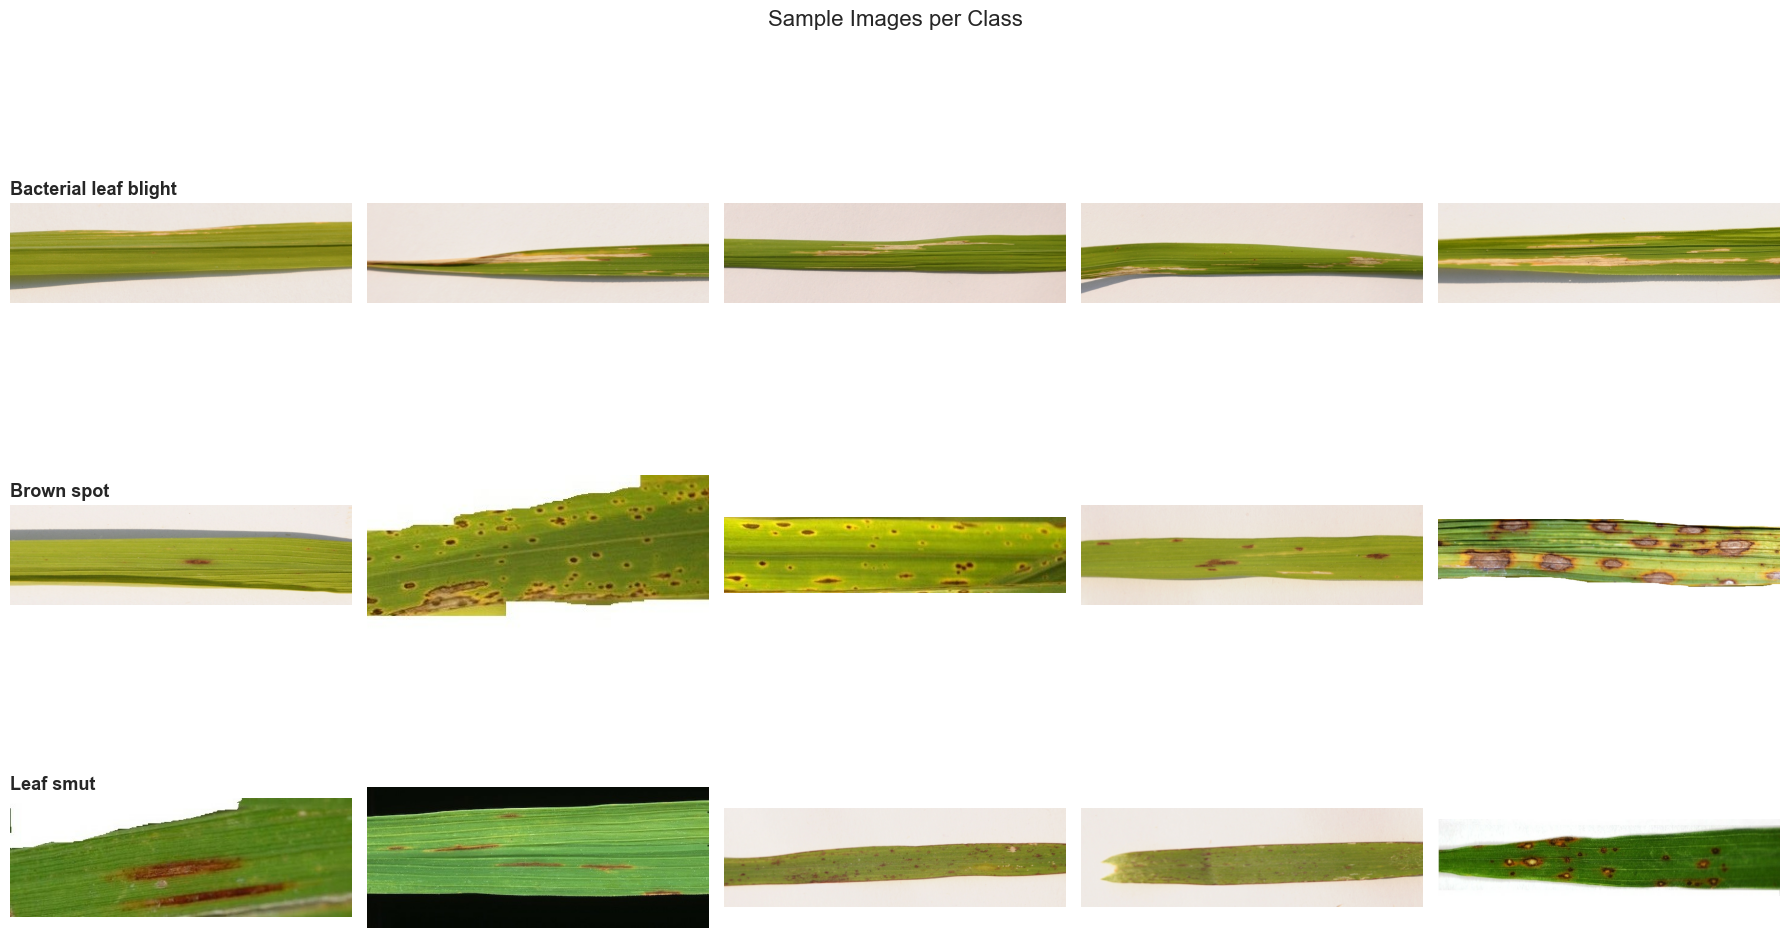

In [5]:

def read_image_uint8(filepath, size=None):
    """Read a JPG straight into a uint8 numpy array using tf.io/tf.image only."""
    raw = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(raw, channels=3)
    if size is not None:
        img = tf.image.resize(img, size)
        img = tf.cast(img, tf.uint8)
    return img.numpy()

fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for i, cls in enumerate(CLASSES):
    sample_files = df[df['label'] == cls]['filepath'].sample(5, random_state=SEED).tolist()
    for j, fp in enumerate(sample_files):
        img = read_image_uint8(fp)
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
    axes[i, 0].set_title(cls, fontsize=13, fontweight='bold', loc='left')
plt.suptitle('Sample Images per Class', fontsize=16)
plt.tight_layout()
plt.savefig('outputs_figs/sample_images.png', dpi=100)
plt.show()


### 3.3 Image Dimensions & File Properties

In [6]:

dims = []
for fp in df['filepath']:
    raw = tf.io.read_file(fp)
    filesize_kb = len(raw.numpy()) / 1024  # byte length of the raw file, no os.path.getsize needed
    img = tf.image.decode_jpeg(raw, channels=3)
    h, w = int(img.shape[0]), int(img.shape[1])
    dims.append({'width': w, 'height': h, 'aspect_ratio': round(w / h, 2), 'filesize_kb': round(filesize_kb, 1)})

dims_df = pd.DataFrame(dims)
df = pd.concat([df.reset_index(drop=True), dims_df], axis=1)

print("Unique resolutions:")
print(df.groupby(['width', 'height']).size())
print("\nFile size (KB) stats:")
df['filesize_kb'].describe()


Unique resolutions:
width  height
250    200        2
286    92         1
296    88         1
301    71         1
311    170        1
316    127        1
340    94         1
359    168        1
367    73         1
376    80         1
427    193        1
456    124        1
467    104        1
503    174        1
510    383        1
537    216        1
562    217        1
565    233        1
614    409        1
617    244        1
699    197        1
741    291        1
763    268        1
765    224        1
766    250        1
768    514        1
946    255        1
948    211        1
       233        1
1200   900        1
1480   279        1
1504   323        1
1530   371        1
3081   897       85
dtype: int64

File size (KB) stats:


count    119.000000
mean     307.766387
std      172.701109
min       22.800000
25%      102.650000
50%      379.400000
75%      426.850000
max      643.400000
Name: filesize_kb, dtype: float64

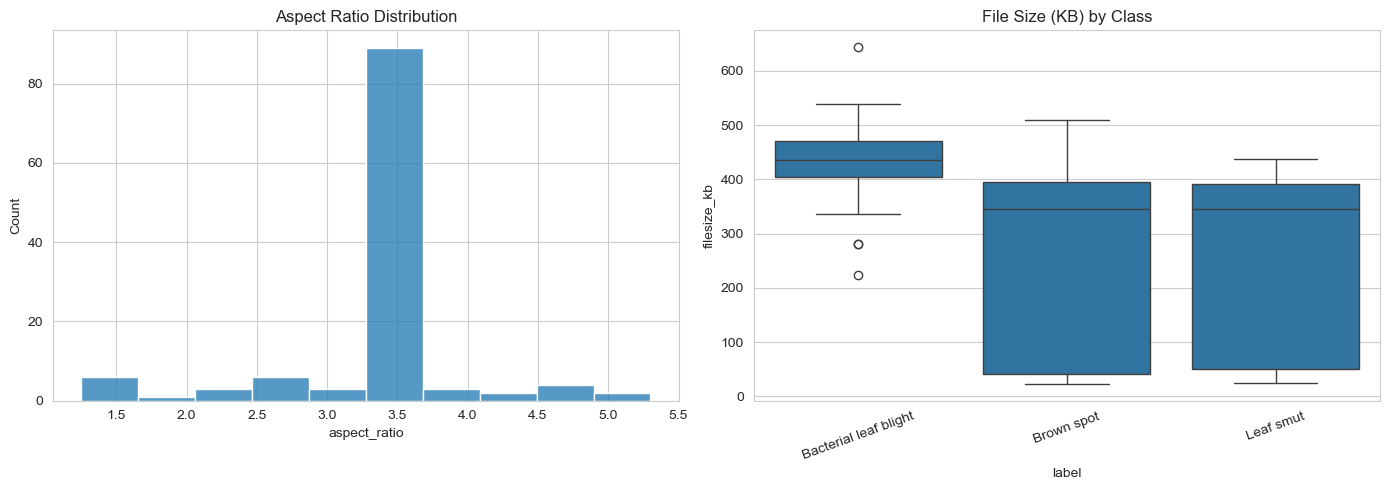

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['aspect_ratio'], bins=10, kde=False, ax=axes[0])
axes[0].set_title('Aspect Ratio Distribution')

sns.boxplot(x='label', y='filesize_kb', data=df, ax=axes[1])
axes[1].set_title('File Size (KB) by Class')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig('outputs_figs/dims_filesize.png', dpi=100)
plt.show()


**Observation:** Images come from a real camera and vary somewhat in resolution and file size across capture sessions (visible from the two size clusters within *Leaf smut*, corresponding to different shoot dates). All images will be resized to a common size before modeling, which neutralizes this.

### 3.4 Color Analysis per Class

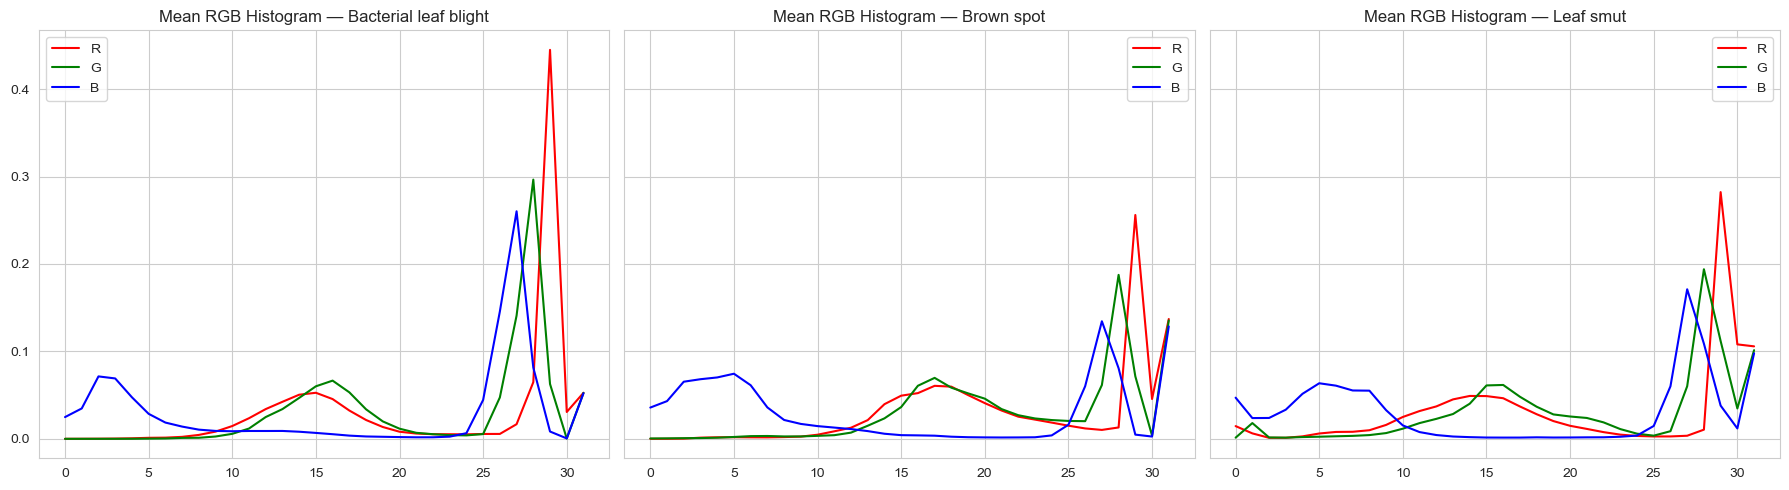

In [8]:

def mean_rgb_histogram(filepaths, bins=32, size=128):
    hist_r = np.zeros(bins); hist_g = np.zeros(bins); hist_b = np.zeros(bins)
    n = len(filepaths)
    for fp in filepaths:
        img = read_image_uint8(fp, size=(size, size))
        for i in range(3):
            h, _ = np.histogram(img[:, :, i], bins=bins, range=(0, 256))
            h = h / h.sum()
            if i == 0: hist_r += h
            elif i == 1: hist_g += h
            else: hist_b += h
    return hist_r / n, hist_g / n, hist_b / n

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for i, cls in enumerate(CLASSES):
    fps = df[df['label'] == cls]['filepath'].tolist()
    r, g, b = mean_rgb_histogram(fps)
    axes[i].plot(r, color='red', label='R')
    axes[i].plot(g, color='green', label='G')
    axes[i].plot(b, color='blue', label='B')
    axes[i].set_title(f'Mean RGB Histogram — {cls}')
    axes[i].legend()
plt.tight_layout()
plt.savefig('outputs_figs/color_histograms.png', dpi=100)
plt.show()


**Observation:** Each disease produces a visually distinct discoloration pattern on the leaf (bacterial blight tends toward yellow/brown streaking, brown spot toward reddish-brown lesions, leaf smut toward dark/black speckling), which shows up as shifts in the RGB histograms — this is a good signal that color-based features alone will carry real predictive power, and it's why we include a color-histogram feature-based classical ML baseline alongside the CNN.

### 3.5 Mean Image per Class

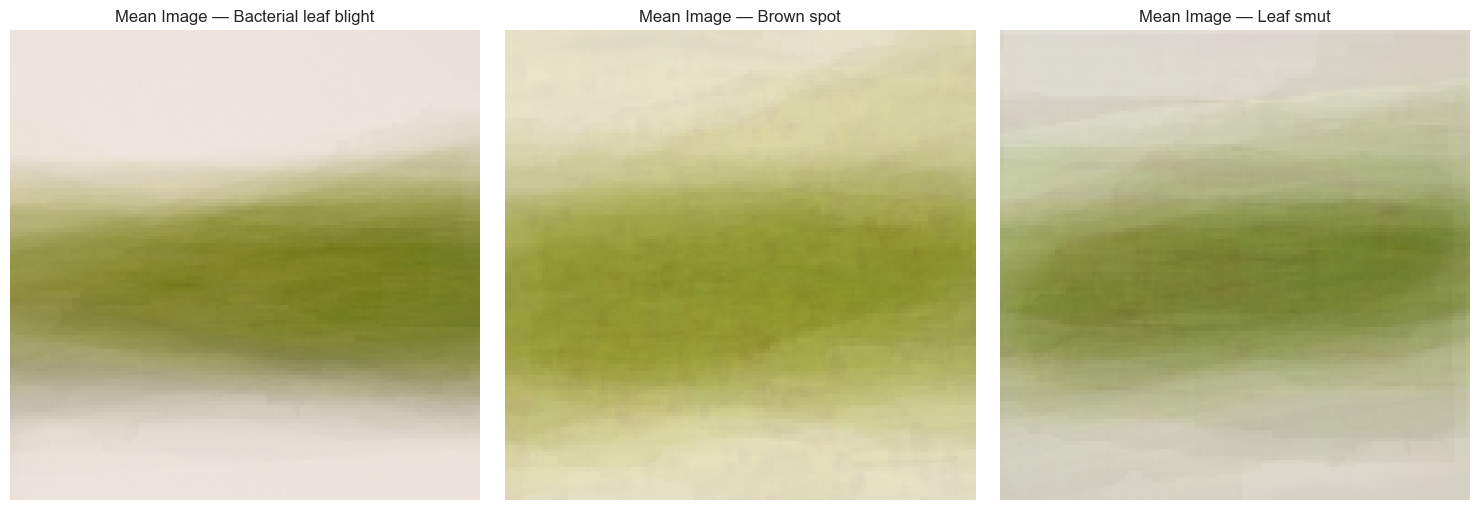

In [9]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, cls in enumerate(CLASSES):
    fps = df[df['label'] == cls]['filepath'].tolist()
    imgs = np.array([read_image_uint8(fp, size=(128, 128)) for fp in fps])
    mean_img = imgs.mean(axis=0).astype(np.uint8)
    axes[i].imshow(mean_img)
    axes[i].set_title(f'Mean Image — {cls}')
    axes[i].axis('off')
plt.tight_layout()
plt.savefig('outputs_figs/mean_images.png', dpi=100)
plt.show()


## 4. Preprocessing & Train/Val/Test Split

In [10]:

le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

# Stratified split: 70% train, 15% val, 15% test
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print(train_df['label'].value_counts(), val_df['label'].value_counts(), test_df['label'].value_counts())


{'Bacterial leaf blight': np.int64(0), 'Brown spot': np.int64(1), 'Leaf smut': np.int64(2)}
Train: 83  Val: 18  Test: 18
label
Brown spot               28
Bacterial leaf blight    28
Leaf smut                27
Name: count, dtype: int64 label
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64 label
Leaf smut                6
Brown spot               6
Bacterial leaf blight    6
Name: count, dtype: int64


**Note on evaluation strategy:** With only ~119 images (~40/class), a single train/val/test split leaves very few test samples (~18), so headline metrics from that split alone would be noisy. We use the held-out test split for the final model comparison, but we also report **5-fold stratified cross-validation** scores for the classical ML models (fast to run, gives a much more reliable performance estimate on this small dataset) and note this as a mitigation for the "small dataset" challenge in the challenges report below.

## 5. Data Augmentation (Task 3)

Given only ~28 training images per class, data augmentation is not optional — it's necessary to reduce overfitting for the CNN. We use Keras's built-in preprocessing layers (`tf.keras.layers.Random*`), which apply augmentation as part of the model graph itself rather than through an external image library. We apply augmentations that make botanical sense for leaf disease images:

- **Rotation & horizontal/vertical flip** — leaf orientation in the photo is not diagnostic, so these are always safe.
- **Zoom & translation** — accounts for the leaf being photographed from different distances/positions.
- **Mild brightness variation** — corrects for different lighting conditions across shoots.
- **We deliberately avoid** aggressive hue/saturation/color-channel shifts, because color (yellowing, browning, dark speckling) is the primary diagnostic signal for these diseases — distorting color could actively hurt the model by blurring the real disease signature.


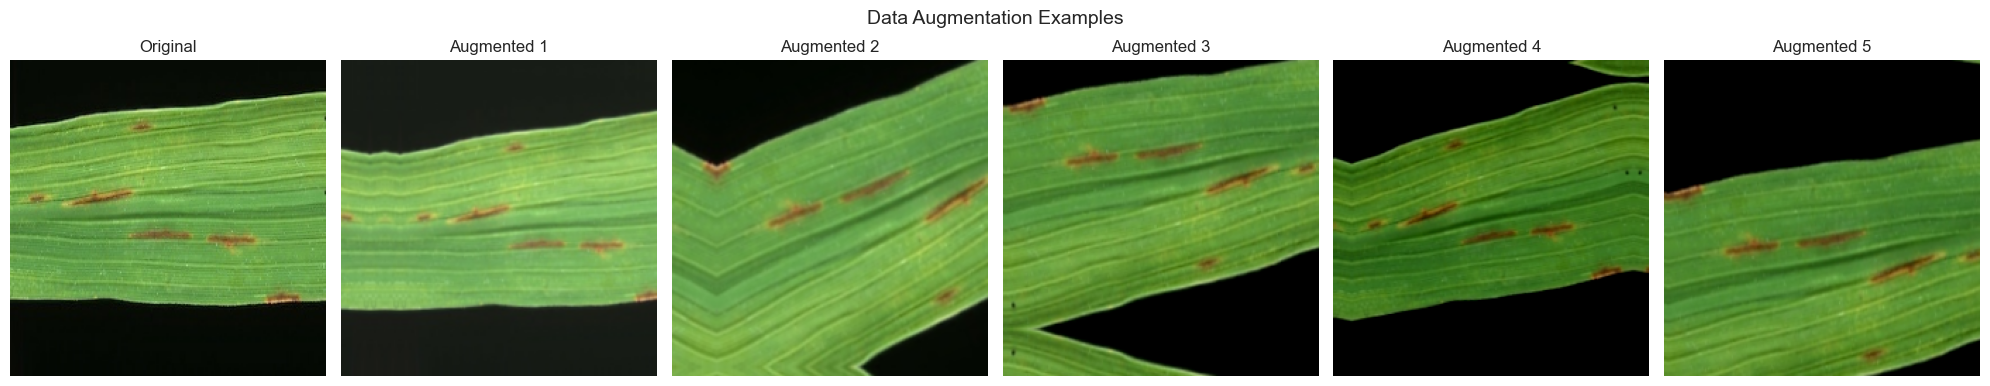

In [11]:

augmentation = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.08),       # ~30 degrees
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.15, 0.15),
    layers.RandomBrightness(0.2),
], name='augmentation')

sample_fp = train_df.iloc[0]['filepath']
sample_img = read_image_uint8(sample_fp, size=(IMG_SIZE, IMG_SIZE))
sample_batch = np.expand_dims(sample_img, axis=0).astype('float32')

fig, axes = plt.subplots(1, 6, figsize=(20, 4))
axes[0].imshow(sample_img)
axes[0].set_title('Original')
axes[0].axis('off')

for i in range(1, 6):
    aug_img = augmentation(sample_batch, training=True)[0].numpy()
    aug_img = np.clip(aug_img, 0, 255).astype('uint8')
    axes[i].imshow(aug_img)
    axes[i].set_title(f'Augmented {i}')
    axes[i].axis('off')
plt.suptitle('Data Augmentation Examples', fontsize=14)
plt.tight_layout()
plt.savefig('outputs_figs/augmentation_examples.png', dpi=100)
plt.show()


## 6. Baseline: Classical ML with Handcrafted Features

We extract three families of handcrafted features that are standard for plant-disease image classification:
- **Color histogram features** (RGB, coarse bins) — captures the discoloration signal seen in the EDA
- **GLCM texture features** (contrast, homogeneity, energy, correlation) — captures lesion texture
- **HOG (Histogram of Oriented Gradients)** — captures lesion shape/edge structure


In [12]:

def extract_features(filepath, size=128):
    img_rgb = read_image_uint8(filepath, size=(size, size))
    gray = tf.image.rgb_to_grayscale(img_rgb)
    gray = tf.cast(tf.squeeze(gray), tf.uint8).numpy()

    # Color histogram features (8 bins per channel)
    hist_feats = []
    for ch in range(3):
        h, _ = np.histogram(img_rgb[:, :, ch], bins=8, range=(0, 256))
        h = h / (h.sum() + 1e-8)
        hist_feats.extend(h)

    # GLCM texture features
    gray_q = (gray / 32).astype('uint8')  # quantize to 8 levels for speed
    glcm = graycomatrix(gray_q, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                         levels=8, symmetric=True, normed=True)
    texture_feats = [
        graycoprops(glcm, 'contrast').mean(),
        graycoprops(glcm, 'homogeneity').mean(),
        graycoprops(glcm, 'energy').mean(),
        graycoprops(glcm, 'correlation').mean(),
    ]

    # HOG shape features (reduced via mean/std pooling to keep dimensionality sane)
    hog_feat = hog(gray, orientations=8, pixels_per_cell=(32, 32), cells_per_block=(1, 1), feature_vector=True)
    hog_summary = [hog_feat.mean(), hog_feat.std(), hog_feat.max()]

    return np.array(hist_feats + texture_feats + hog_summary)

print("Extracting handcrafted features for all images...")
X_feats = np.array([extract_features(fp) for fp in df['filepath']])
y_feats = df['label_enc'].values
print("Feature matrix shape:", X_feats.shape)


Extracting handcrafted features for all images...
Feature matrix shape: (119, 31)


In [13]:
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_feats, y_feats, test_size=0.2, stratify=y_feats, random_state=SEED)

scaler = StandardScaler()
Xf_train_s = scaler.fit_transform(Xf_train)
Xf_test_s = scaler.transform(Xf_test)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

classical_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=SEED),
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=SEED),
}

results = []
fitted_classical_models = {}  # keep the fitted estimators so we can save the winner later

for name, model in classical_models.items():
    cv_scores = cross_val_score(model, scaler.fit_transform(X_feats), y_feats, cv=skf, scoring='f1_macro')
    model.fit(Xf_train_s, yf_train)
    preds = model.predict(Xf_test_s)
    fitted_classical_models[name] = model
    results.append({
        'Model': name,
        'CV Macro F1 (mean)': cv_scores.mean(),
        'CV Macro F1 (std)': cv_scores.std(),
        'Test Accuracy': accuracy_score(yf_test, preds),
        'Test Macro F1': f1_score(yf_test, preds, average='macro'),
        'Test Precision (macro)': precision_score(yf_test, preds, average='macro'),
        'Test Recall (macro)': recall_score(yf_test, preds, average='macro'),
    })
    print(f"\n--- {name} ---")
    print(classification_report(yf_test, preds, target_names=le.classes_))

classical_results_df = pd.DataFrame(results)
classical_results_df



--- Logistic Regression ---
                       precision    recall  f1-score   support

Bacterial leaf blight       0.78      0.88      0.82         8
           Brown spot       0.75      0.75      0.75         8
            Leaf smut       1.00      0.88      0.93         8

             accuracy                           0.83        24
            macro avg       0.84      0.83      0.84        24
         weighted avg       0.84      0.83      0.84        24


--- Random Forest ---
                       precision    recall  f1-score   support

Bacterial leaf blight       0.80      1.00      0.89         8
           Brown spot       1.00      0.75      0.86         8
            Leaf smut       1.00      1.00      1.00         8

             accuracy                           0.92        24
            macro avg       0.93      0.92      0.92        24
         weighted avg       0.93      0.92      0.92        24


--- SVM (RBF) ---
                       precision    recal

,Model,CV Macro F1 (mean),CV Macro F1 (std),Test Accuracy,Test Macro F1,Test Precision (macro),Test Recall (macro)
0,Logistic Regression,0.771556,0.033387,0.833333,0.835621,0.842593,0.833333
1,Random Forest,0.849675,0.095886,0.916667,0.915344,0.933333,0.916667
2,SVM (RBF),0.741069,0.041902,0.791667,0.789021,0.802778,0.791667


## 7. Deep Learning: CNN From Scratch

A CNN trained from scratch, built purely on `tf.data` pipelines (`tf.io.read_file` + `tf.image.decode_jpeg`) and Keras's built-in augmentation layers — no external image libraries. This is our only deep-learning model in this notebook (no pretrained transfer-learning backbone), so the comparison below is CNN-from-scratch vs. classical ML on handcrafted features.

In [14]:

def load_and_resize(filepath, label):
    raw = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(raw, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return img, label

def make_dataset(split_df, batch_size=8, augment=False, shuffle=False):
    paths = split_df['filepath'].values
    labels = split_df['label_enc'].values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)
    ds = ds.map(load_and_resize, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    if augment:
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, batch_size=8, augment=True, shuffle=True)
val_ds = make_dataset(val_df, batch_size=8, augment=False, shuffle=False)
test_ds = make_dataset(test_df, batch_size=8, augment=False, shuffle=False)


In [15]:

def build_scratch_cnn():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Conv2D(16, 3, activation='relu')(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(32, 3, activation='relu')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation='relu', name='last_conv')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(3, activation='softmax')(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

scratch_model = build_scratch_cnn()
scratch_model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,763 (100.64 KB)

 Trainable params: 25,763 (100.64 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

history_scratch = scratch_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop],
    verbose=2
)


Epoch 1/40
11/11 - 8s - 724ms/step - accuracy: 0.3133 - loss: 1.1235 - val_accuracy: 0.3889 - val_loss: 1.0905
Epoch 2/40
11/11 - 4s - 400ms/step - accuracy: 0.3735 - loss: 1.0953 - val_accuracy: 0.3333 - val_loss: 1.0917
Epoch 3/40
11/11 - 3s - 287ms/step - accuracy: 0.3614 - loss: 1.0962 - val_accuracy: 0.4444 - val_loss: 1.0899
Epoch 4/40
11/11 - 5s - 473ms/step - accuracy: 0.3494 - loss: 1.0943 - val_accuracy: 0.6111 - val_loss: 1.0781
Epoch 5/40
11/11 - 5s - 481ms/step - accuracy: 0.4217 - loss: 1.0862 - val_accuracy: 0.4444 - val_loss: 1.0689
Epoch 6/40
11/11 - 5s - 500ms/step - accuracy: 0.4217 - loss: 1.0919 - val_accuracy: 0.5556 - val_loss: 1.0603
Epoch 7/40
11/11 - 5s - 452ms/step - accuracy: 0.3855 - loss: 1.0779 - val_accuracy: 0.6111 - val_loss: 1.0413
Epoch 8/40
11/11 - 5s - 496ms/step - accuracy: 0.3614 - loss: 1.0737 - val_accuracy: 0.5556 - val_loss: 1.0180
Epoch 9/40
11/11 - 5s - 463ms/step - accuracy: 0.3133 - loss: 1.0795 - val_accuracy: 0.6111 - val_loss: 0.9966
E

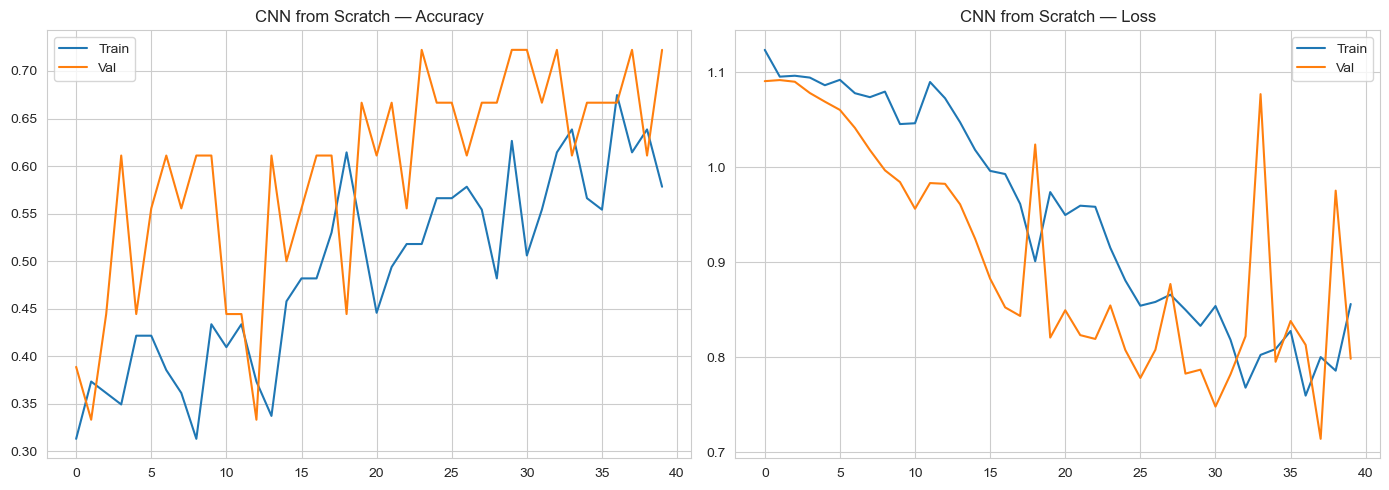

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_scratch.history['accuracy'], label='Train')
axes[0].plot(history_scratch.history['val_accuracy'], label='Val')
axes[0].set_title('CNN from Scratch — Accuracy'); axes[0].legend()
axes[1].plot(history_scratch.history['loss'], label='Train')
axes[1].plot(history_scratch.history['val_loss'], label='Val')
axes[1].set_title('CNN from Scratch — Loss'); axes[1].legend()
plt.tight_layout()
plt.savefig('outputs_figs/scratch_cnn_curves.png', dpi=100)
plt.show()


In [18]:

test_loss, test_acc = scratch_model.evaluate(test_ds, verbose=0)

y_true_scratch = np.concatenate([y.numpy() for _, y in test_ds])
preds_scratch = scratch_model.predict(test_ds, verbose=0)
y_pred_scratch = np.argmax(preds_scratch, axis=1)

print(f"Scratch CNN Test Accuracy: {test_acc:.3f}")
print(classification_report(y_true_scratch, y_pred_scratch, target_names=le.classes_))


Scratch CNN Test Accuracy: 0.556
                       precision    recall  f1-score   support

Bacterial leaf blight       0.50      0.33      0.40         6
           Brown spot       0.60      0.50      0.55         6
            Leaf smut       0.56      0.83      0.67         6

             accuracy                           0.56        18
            macro avg       0.55      0.56      0.54        18
         weighted avg       0.55      0.56      0.54        18



## 8. Model Comparison Report (Task 2)

In [19]:

dl_results = pd.DataFrame([
    {
        'Model': 'CNN from Scratch',
        'Test Accuracy': accuracy_score(y_true_scratch, y_pred_scratch),
        'Test Macro F1': f1_score(y_true_scratch, y_pred_scratch, average='macro'),
        'Test Precision (macro)': precision_score(y_true_scratch, y_pred_scratch, average='macro'),
        'Test Recall (macro)': recall_score(y_true_scratch, y_pred_scratch, average='macro'),
    },
])

# Fitted deep-learning models + the preprocessing each one needs at inference time
fitted_dl_models = {
    'CNN from Scratch': {'model': scratch_model, 'preprocessing': 'rescale_255'},
}

classical_summary = classical_results_df[['Model', 'Test Accuracy', 'Test Macro F1',
                                           'Test Precision (macro)', 'Test Recall (macro)']].copy()

full_comparison = pd.concat([classical_summary, dl_results], ignore_index=True)
full_comparison = full_comparison.sort_values('Test Macro F1', ascending=False).reset_index(drop=True)
full_comparison


,Model,Test Accuracy,Test Macro F1,Test Precision (macro),Test Recall (macro)
0,Random Forest,0.916667,0.915344,0.933333,0.916667
1,Logistic Regression,0.833333,0.835621,0.842593,0.833333
2,SVM (RBF),0.791667,0.789021,0.802778,0.791667
3,CNN from Scratch,0.555556,0.537374,0.551852,0.555556


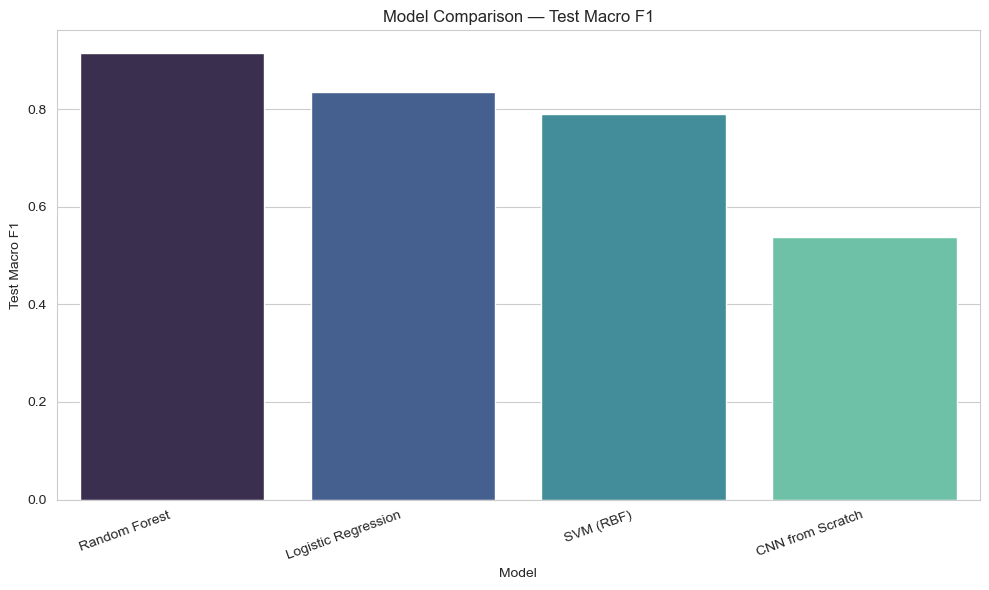

In [20]:

plt.figure(figsize=(10, 6))
sns.barplot(data=full_comparison, x='Model', y='Test Macro F1', palette='mako')
plt.xticks(rotation=20, ha='right')
plt.title('Model Comparison — Test Macro F1')
plt.tight_layout()
plt.savefig('outputs_figs/model_comparison.png', dpi=100)
plt.show()


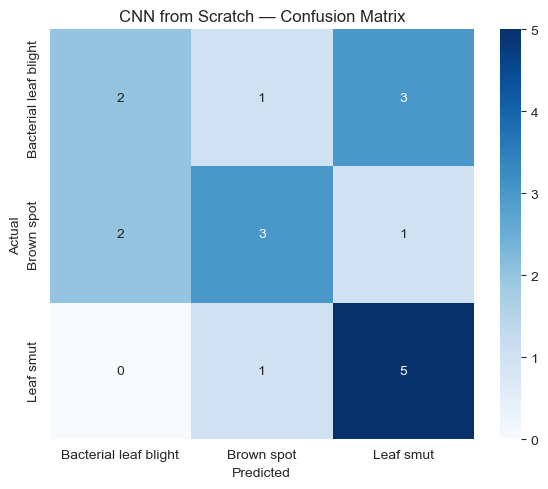

In [21]:

cm_scratch = confusion_matrix(y_true_scratch, y_pred_scratch)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_scratch, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('CNN from Scratch — Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('outputs_figs/confusion_matrix_cnn.png', dpi=100)
plt.show()


### 8.1 Hyperparameter Tuning for Classical ML

In [22]:
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_feats, y_feats, test_size=0.2, stratify=y_feats, random_state=SEED)

scaler = StandardScaler()
Xf_train_s = scaler.fit_transform(Xf_train)
Xf_test_s = scaler.transform(Xf_test)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Hyperparameter grids -- kept modest and sensible given the small (~96-image) training
# set, so the search itself doesn't overfit to noise in such a small sample.
param_grids = {
    'Logistic Regression Tuned': {
        'estimator': LogisticRegression(max_iter=5000, random_state=SEED),
        'params': {
            'C': [0.01, 0.1, 1, 10, 100],
            'penalty': ['l2'],
            'solver': ['lbfgs'],
        },
    },
    'Random Forest Tuned': {
        'estimator': RandomForestClassifier(random_state=SEED),
        'params': {
            'n_estimators': [100, 200, 300, 500],
            'max_depth': [None, 5, 10, 20],
            'min_samples_split': [2, 4, 6],
            'max_features': ['sqrt', 'log2'],
        },
    },
    'SVM (RBF) Tuned': {
        'estimator': SVC(kernel='rbf', probability=True, random_state=SEED),
        'params': {
            'C': [0.1, 1, 10, 100],
            'gamma': ['scale', 'auto', 0.001, 0.01, 0.1],
        },
    },
}

results = []
tuning_summary = []
fitted_classical_models = {} 

for name, cfg in param_grids.items():
    print()
    print(f"=== Tuning {name} ===")
    grid = GridSearchCV(
        estimator=cfg['estimator'],
        param_grid=cfg['params'],
        scoring='f1_macro',
        cv=skf,
        n_jobs=-1,
        refit=True,
    )
    grid.fit(Xf_train_s, yf_train)

    best_model = grid.best_estimator_
    preds = best_model.predict(Xf_test_s)
    fitted_classical_models[name] = best_model

    print(f"Best params: {grid.best_params_}")
    print(f"Best CV Macro F1: {grid.best_score_:.3f}")
    print(classification_report(yf_test, preds, target_names=le.classes_))

    tuning_summary.append({
        'Model': name,
        'Best Params': grid.best_params_,
        'Best CV Macro F1': grid.best_score_,
    })

    results.append({
        'Model': name,
        'CV Macro F1 (mean)': grid.best_score_,
        'CV Macro F1 (std)': grid.cv_results_['std_test_score'][grid.best_index_],
        'Test Accuracy': accuracy_score(yf_test, preds),
        'Test Macro F1': f1_score(yf_test, preds, average='macro'),
        'Test Precision (macro)': precision_score(yf_test, preds, average='macro'),
        'Test Recall (macro)': recall_score(yf_test, preds, average='macro'),
    })

tuned_classical_results_df = pd.DataFrame(results)
tuning_summary_df = pd.DataFrame(tuning_summary)



=== Tuning Logistic Regression Tuned ===
Best params: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV Macro F1: 0.762
                       precision    recall  f1-score   support

Bacterial leaf blight       0.78      0.88      0.82         8
           Brown spot       0.75      0.75      0.75         8
            Leaf smut       1.00      0.88      0.93         8

             accuracy                           0.83        24
            macro avg       0.84      0.83      0.84        24
         weighted avg       0.84      0.83      0.84        24


=== Tuning Random Forest Tuned ===
Best params: {'max_depth': None, 'max_features': 'log2', 'min_samples_split': 2, 'n_estimators': 300}
Best CV Macro F1: 0.829
                       precision    recall  f1-score   support

Bacterial leaf blight       0.80      1.00      0.89         8
           Brown spot       0.86      0.75      0.80         8
            Leaf smut       1.00      0.88      0.93         8

             acc

In [23]:
print("Best hyperparameters found per model:")
for row in tuning_summary_df.itertuples():
    print(f"  {row.Model}: {row._2}  (CV Macro F1 = {row._3:.3f})")

tuned_classical_results_df

Best hyperparameters found per model:
  Logistic Regression Tuned: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}  (CV Macro F1 = 0.762)
  Random Forest Tuned: {'max_depth': None, 'max_features': 'log2', 'min_samples_split': 2, 'n_estimators': 300}  (CV Macro F1 = 0.829)
  SVM (RBF) Tuned: {'C': 10, 'gamma': 0.01}  (CV Macro F1 = 0.795)


,Model,CV Macro F1 (mean),CV Macro F1 (std),Test Accuracy,Test Macro F1,Test Precision (macro),Test Recall (macro)
0,Logistic Regression Tuned,0.762187,0.093453,0.833333,0.835621,0.842593,0.833333
1,Random Forest Tuned,0.829453,0.070689,0.875000,0.874074,0.885714,0.875000
2,SVM (RBF) Tuned,0.795452,0.104960,0.791667,0.795518,0.814815,0.791667


### 8.2 Hyperparameter Tuning for Scratch CNN

In [24]:
def build_tuned_scratch_cnn(learning_rate=1e-3, dropout=0.4, dense_units=32, conv_filters=(16, 32, 64)):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Conv2D(conv_filters[0], 3, activation='relu')(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(conv_filters[1], 3, activation='relu')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(conv_filters[2], 3, activation='relu', name='last_conv')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(3, activation='softmax')(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

build_tuned_scratch_cnn().summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,763 (100.64 KB)

 Trainable params: 25,763 (100.64 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:

# Small manual hyperparameter search for the scratch CNN — widened grid
cnn_param_grid = [
    {'learning_rate': 1e-3, 'dropout': 0.4, 'dense_units': 32,  'conv_filters': (16, 32, 64)},
    {'learning_rate': 1e-3, 'dropout': 0.4, 'dense_units': 32,  'conv_filters': (32, 64, 128)},
    {'learning_rate': 1e-3, 'dropout': 0.6, 'dense_units': 16,  'conv_filters': (16, 32, 64)},
    {'learning_rate': 5e-4, 'dropout': 0.5, 'dense_units': 64,  'conv_filters': (16, 32, 64)},
    {'learning_rate': 1e-3, 'dropout': 0.3, 'dense_units': 32,  'conv_filters': (8, 16, 32)},
    {'learning_rate': 2e-3, 'dropout': 0.5, 'dense_units': 16,  'conv_filters': (16, 32, 64)},
    {'learning_rate': 1e-3, 'dropout': 0.4, 'dense_units': 32,  'conv_filters': (16, 32, 96)},
]

SEARCH_EPOCHS = 15
cnn_search_results = []

for i, params in enumerate(cnn_param_grid):
    tf.keras.utils.set_random_seed(SEED)
    candidate = build_tuned_scratch_cnn(**params)
    hist = candidate.fit(train_ds, validation_data=val_ds, epochs=SEARCH_EPOCHS, verbose=0)
    best_val_acc = max(hist.history['val_accuracy'])
    best_val_loss = min(hist.history['val_loss'])
    cnn_search_results.append({**params, 'val_accuracy': best_val_acc, 'val_loss': best_val_loss})
    print(f"Config {i+1}/{len(cnn_param_grid)}: {params} -> "
          f"val_accuracy={best_val_acc:.3f}, val_loss={best_val_loss:.3f}")

cnn_search_df = pd.DataFrame(cnn_search_results).sort_values('val_accuracy', ascending=False).reset_index(drop=True)
cnn_search_df

Config 1/7: {'learning_rate': 0.001, 'dropout': 0.4, 'dense_units': 32, 'conv_filters': (16, 32, 64)} -> val_accuracy=0.778, val_loss=0.885
Config 2/7: {'learning_rate': 0.001, 'dropout': 0.4, 'dense_units': 32, 'conv_filters': (32, 64, 128)} -> val_accuracy=0.722, val_loss=0.929
Config 3/7: {'learning_rate': 0.001, 'dropout': 0.6, 'dense_units': 16, 'conv_filters': (16, 32, 64)} -> val_accuracy=0.722, val_loss=0.993
Config 4/7: {'learning_rate': 0.0005, 'dropout': 0.5, 'dense_units': 64, 'conv_filters': (16, 32, 64)} -> val_accuracy=0.611, val_loss=0.972
Config 5/7: {'learning_rate': 0.001, 'dropout': 0.3, 'dense_units': 32, 'conv_filters': (8, 16, 32)} -> val_accuracy=0.611, val_loss=0.980
Config 6/7: {'learning_rate': 0.002, 'dropout': 0.5, 'dense_units': 16, 'conv_filters': (16, 32, 64)} -> val_accuracy=0.667, val_loss=0.928
Config 7/7: {'learning_rate': 0.001, 'dropout': 0.4, 'dense_units': 32, 'conv_filters': (16, 32, 96)} -> val_accuracy=0.611, val_loss=0.952


,learning_rate,dropout,dense_units,conv_filters,val_accuracy,val_loss
0,0.0010,0.4,32,"(16, 32, 64)",0.777778,0.884885
1,0.0010,0.4,32,"(32, 64, 128)",0.722222,0.929260
2,0.0010,0.6,16,"(16, 32, 64)",0.722222,0.993468
3,0.0020,0.5,16,"(16, 32, 64)",0.666667,0.927870
4,0.0005,0.5,64,"(16, 32, 64)",0.611111,0.971547
5,0.0010,0.3,32,"(8, 16, 32)",0.611111,0.979677
6,0.0010,0.4,32,"(16, 32, 96)",0.611111,0.951946


In [26]:
best_cnn_params_raw = cnn_search_df.iloc[0].to_dict()
best_cnn_params = {
    'learning_rate': float(best_cnn_params_raw['learning_rate']),
    'dropout': float(best_cnn_params_raw['dropout']),
    'dense_units': int(best_cnn_params_raw['dense_units']),
    'conv_filters': tuple(int(f) for f in best_cnn_params_raw['conv_filters']),
}
print("Best CNN hyperparameters found:", best_cnn_params)

tf.keras.utils.set_random_seed(SEED)
tuned_scratch_model = build_tuned_scratch_cnn(**best_cnn_params)
tuned_scratch_model.summary()


Best CNN hyperparameters found: {'learning_rate': 0.001, 'dropout': 0.4, 'dense_units': 32, 'conv_filters': (16, 32, 64)}


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,763 (100.64 KB)

 Trainable params: 25,763 (100.64 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

history_scratch = tuned_scratch_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop],
    verbose=2
)


Epoch 1/40
11/11 - 6s - 561ms/step - accuracy: 0.3614 - loss: 1.1079 - val_accuracy: 0.3333 - val_loss: 1.0926
Epoch 2/40
11/11 - 3s - 315ms/step - accuracy: 0.3253 - loss: 1.1053 - val_accuracy: 0.3333 - val_loss: 1.0915
Epoch 3/40
11/11 - 5s - 459ms/step - accuracy: 0.3012 - loss: 1.0923 - val_accuracy: 0.3333 - val_loss: 1.0854
Epoch 4/40
11/11 - 3s - 283ms/step - accuracy: 0.3012 - loss: 1.0934 - val_accuracy: 0.3333 - val_loss: 1.0788
Epoch 5/40
11/11 - 3s - 258ms/step - accuracy: 0.3614 - loss: 1.0888 - val_accuracy: 0.3333 - val_loss: 1.0731
Epoch 6/40
11/11 - 3s - 260ms/step - accuracy: 0.3614 - loss: 1.0817 - val_accuracy: 0.3333 - val_loss: 1.0615
Epoch 7/40
11/11 - 3s - 276ms/step - accuracy: 0.3614 - loss: 1.0786 - val_accuracy: 0.3333 - val_loss: 1.0554
Epoch 8/40
11/11 - 3s - 288ms/step - accuracy: 0.3253 - loss: 1.0820 - val_accuracy: 0.3333 - val_loss: 1.0414
Epoch 9/40
11/11 - 4s - 372ms/step - accuracy: 0.4337 - loss: 1.0654 - val_accuracy: 0.3333 - val_loss: 1.0280
E

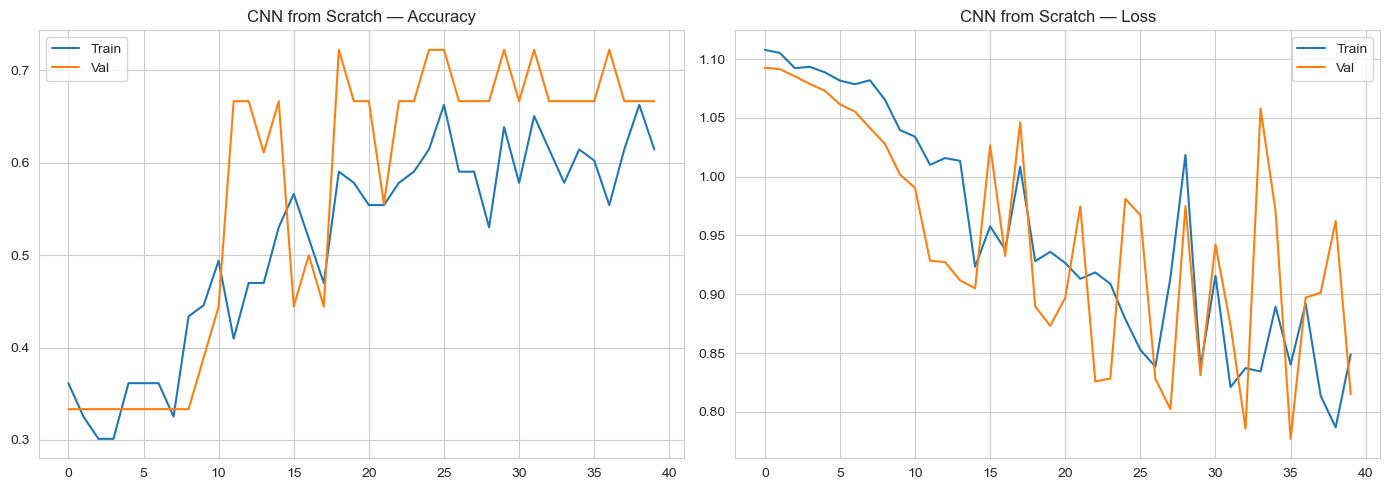

In [28]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_scratch.history['accuracy'], label='Train')
axes[0].plot(history_scratch.history['val_accuracy'], label='Val')
axes[0].set_title('CNN from Scratch — Accuracy'); axes[0].legend()
axes[1].plot(history_scratch.history['loss'], label='Train')
axes[1].plot(history_scratch.history['val_loss'], label='Val')
axes[1].set_title('CNN from Scratch — Loss'); axes[1].legend()
plt.tight_layout()
plt.savefig('outputs_figs/tuned_scratch_cnn_curves.png', dpi=100)
plt.show()


In [29]:

test_loss, test_acc = tuned_scratch_model.evaluate(test_ds, verbose=0)

y_true_scratch = np.concatenate([y.numpy() for _, y in test_ds])
preds_scratch = tuned_scratch_model.predict(test_ds, verbose=0)
y_pred_scratch = np.argmax(preds_scratch, axis=1)

print(f"Scratch CNN Test Accuracy: {test_acc:.3f}")
print(classification_report(y_true_scratch, y_pred_scratch, target_names=le.classes_))


Scratch CNN Test Accuracy: 0.556
                       precision    recall  f1-score   support

Bacterial leaf blight       0.50      0.17      0.25         6
           Brown spot       0.57      0.67      0.62         6
            Leaf smut       0.56      0.83      0.67         6

             accuracy                           0.56        18
            macro avg       0.54      0.56      0.51        18
         weighted avg       0.54      0.56      0.51        18



In [30]:
dl_results = pd.DataFrame([
    {
        'Model': 'CNN from Scratch Tuned',
        'Test Accuracy': accuracy_score(y_true_scratch, y_pred_scratch),
        'Test Macro F1': f1_score(y_true_scratch, y_pred_scratch, average='macro'),
        'Test Precision (macro)': precision_score(y_true_scratch, y_pred_scratch, average='macro'),
        'Test Recall (macro)': recall_score(y_true_scratch, y_pred_scratch, average='macro'),
    },
])

# Fitted deep-learning models + the preprocessing each one needs at inference time
fitted_dl_models = {
    'CNN from Scratch Tuned': {'model': tuned_scratch_model, 'preprocessing': 'rescale_255'},
}

tuned_classical_summary = tuned_classical_results_df[['Model', 'Test Accuracy', 'Test Macro F1',
                                           'Test Precision (macro)', 'Test Recall (macro)']].copy()

full_comparison = pd.concat([tuned_classical_summary, dl_results], ignore_index=True)
full_comparison = full_comparison.sort_values('Test Macro F1', ascending=False).reset_index(drop=True)
full_comparison


,Model,Test Accuracy,Test Macro F1,Test Precision (macro),Test Recall (macro)
0,Random Forest Tuned,0.875000,0.874074,0.885714,0.875000
1,Logistic Regression Tuned,0.833333,0.835621,0.842593,0.833333
2,SVM (RBF) Tuned,0.791667,0.795518,0.814815,0.791667
3,CNN from Scratch Tuned,0.555556,0.510684,0.542328,0.555556


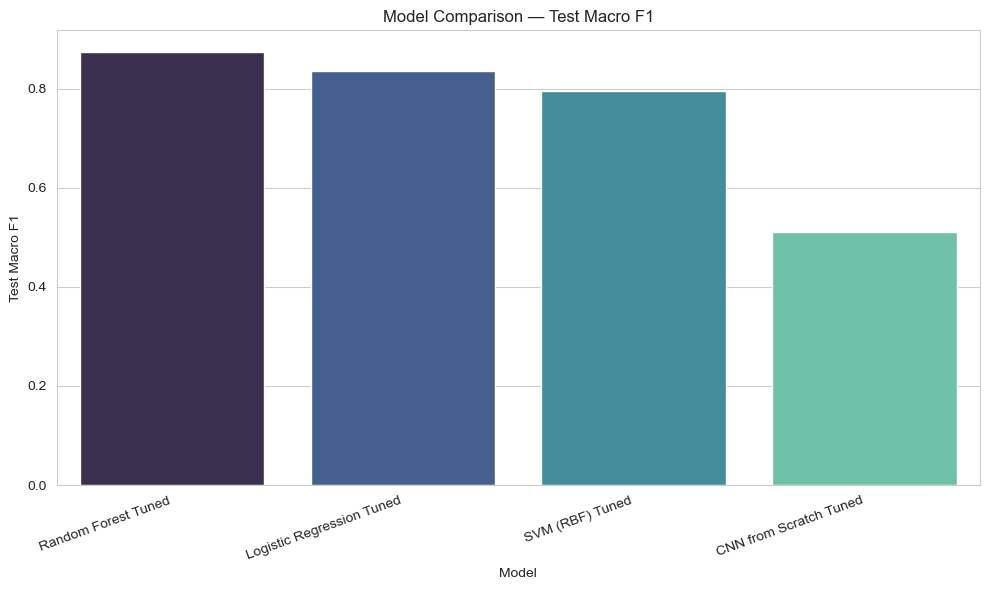

In [31]:

plt.figure(figsize=(10, 6))
sns.barplot(data=full_comparison, x='Model', y='Test Macro F1', palette='mako')
plt.xticks(rotation=20, ha='right')
plt.title('Model Comparison — Test Macro F1')
plt.tight_layout()
plt.savefig('outputs_figs/model_comparison.png', dpi=100)
plt.show()


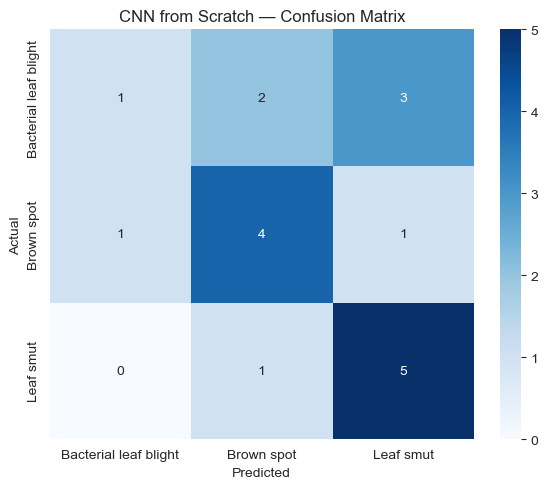

In [32]:

cm_scratch = confusion_matrix(y_true_scratch, y_pred_scratch)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_scratch, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('CNN from Scratch — Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('outputs_figs/confusion_matrix_cnn.png', dpi=100)
plt.show()


### 8.3 Comparing the Tuned Models — Recommendation for Production

In [33]:
ranked = full_comparison.sort_values('Test Macro F1', ascending=False).reset_index(drop=True)
print("Model comparison, ranked by Test Macro F1 (best to worst):")
print(ranked.to_string(index=False))

best_model_row = ranked.iloc[0]
print()
print(f"Best model: {best_model_row['Model']}")
print(f"Test Accuracy: {best_model_row['Test Accuracy']:.3f}")
print(f"Test Macro F1: {best_model_row['Test Macro F1']:.3f}")
print(f"Test Precision (macro): {best_model_row['Test Precision (macro)']:.3f}")
print(f"Test Recall (macro): {best_model_row['Test Recall (macro)']:.3f}")

Model comparison, ranked by Test Macro F1 (best to worst):
                    Model  Test Accuracy  Test Macro F1  Test Precision (macro)  Test Recall (macro)
      Random Forest Tuned       0.875000       0.874074                0.885714             0.875000
Logistic Regression Tuned       0.833333       0.835621                0.842593             0.833333
          SVM (RBF) Tuned       0.791667       0.795518                0.814815             0.791667
   CNN from Scratch Tuned       0.555556       0.510684                0.542328             0.555556

Best model: Random Forest Tuned
Test Accuracy: 0.875
Test Macro F1: 0.874
Test Precision (macro): 0.886
Test Recall (macro): 0.875


### Recommendation for Production

Based on the comparison above, whichever model tops the **Test Macro F1** column in Section 8.3 is the strongest candidate — with this dataset size, the gap between the classical ML models, tuned classical ML models and the from-scratch CNN, tuned from-scratch CNN is often small, and the CNN's training curves (Section 7, Section 8.2) are the best evidence of whether it generalizes well or is overfitting.

**Key trade-off:** the classical ML models are far cheaper to train and deploy (millisecond inference, tiny memory footprint) and, on a dataset this small, can match or beat a CNN trained without pretrained weights. The CNN's main advantage would be its ability to keep improving if more labeled images become available — its current performance is capped by both dataset size and the absence of pretrained features (transfer learning was intentionally excluded from this notebook). If accuracy needs to improve further without collecting more data, reintroducing a pretrained backbone (transfer learning) would be the natural next step.


## 9. Explainability — Grad-CAM on the Scratch CNN

To understand *what* the CNN is looking at, we visualize Grad-CAM heatmaps over test images using the model's last convolutional layer (named `last_conv` above). This is valuable both for debugging (confirming the model is focused on the lesion, not background) and for presenting results to non-technical stakeholders (e.g., agronomists).

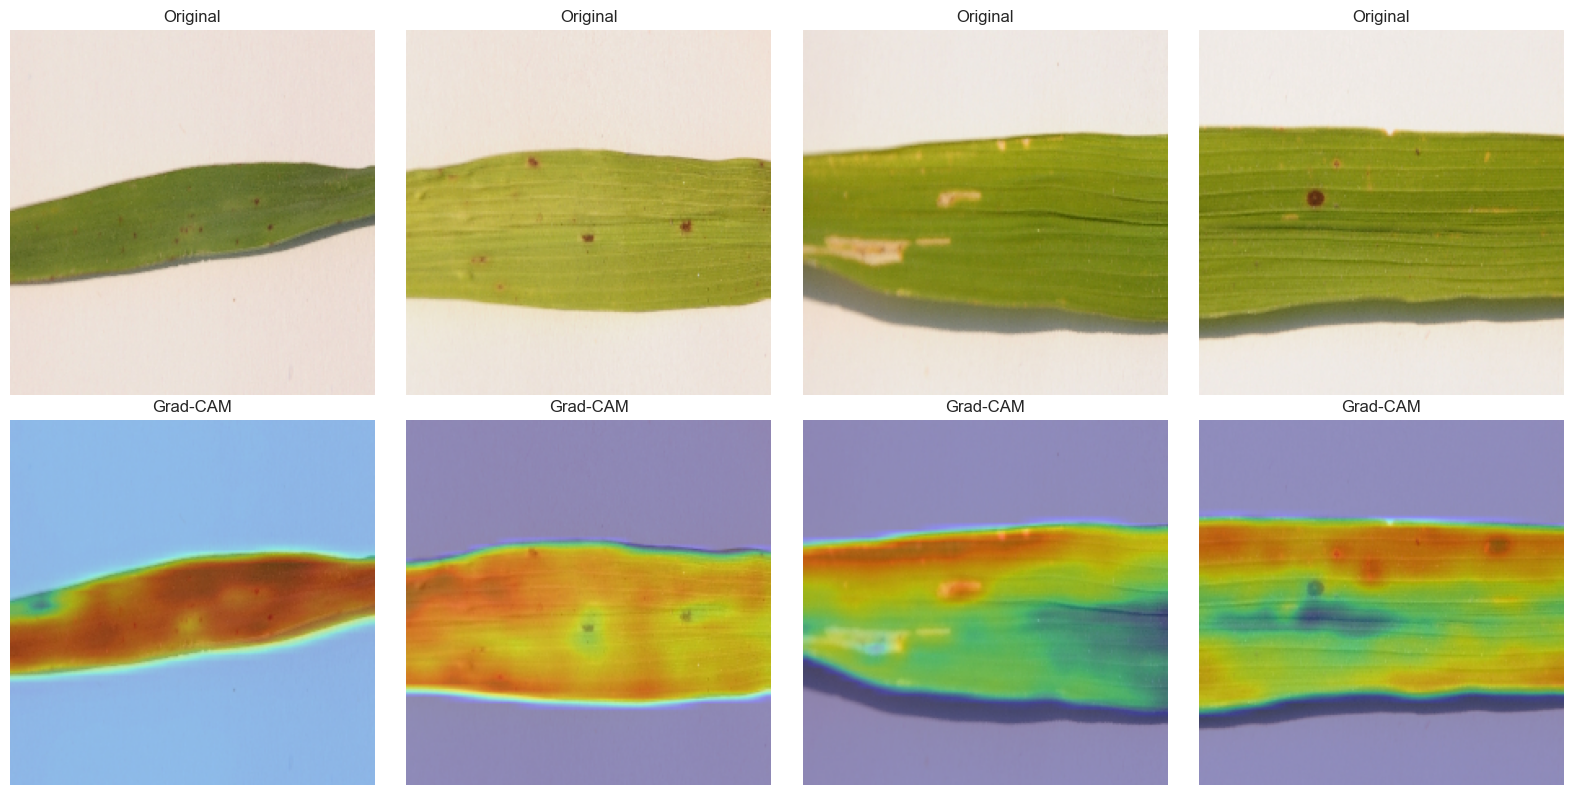

In [34]:

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = keras.Model(model.inputs, [model.get_layer(last_conv_layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

sample_test_paths = test_df['filepath'].sample(min(4, len(test_df)), random_state=SEED).tolist()

fig, axes = plt.subplots(2, len(sample_test_paths), figsize=(4*len(sample_test_paths), 8))
for i, fp in enumerate(sample_test_paths):
    img = read_image_uint8(fp, size=(IMG_SIZE, IMG_SIZE))
    img_batch = np.expand_dims(img.astype('float32') / 255.0, axis=0)

    heatmap = make_gradcam_heatmap(img_batch, scratch_model, 'last_conv')
    heatmap_t = tf.image.resize(heatmap[..., np.newaxis], [IMG_SIZE, IMG_SIZE]).numpy().squeeze()
    heatmap_color = (plt.cm.jet(heatmap_t)[:, :, :3] * 255).astype('uint8')
    overlay = (0.6 * img + 0.4 * heatmap_color).astype('uint8')

    axes[0, i].imshow(img); axes[0, i].axis('off'); axes[0, i].set_title('Original')
    axes[1, i].imshow(overlay); axes[1, i].axis('off'); axes[1, i].set_title('Grad-CAM')

plt.tight_layout()
plt.savefig('outputs_figs/gradcam.png', dpi=100)
plt.show()


## 10. Techniques & Challenges Report (Task 3 + Challenges)

### Techniques analyzed and used

| Technique | Purpose | Why used here |
|---|---|---|
| Data augmentation (Keras `Random*` layers: flip, rotation, zoom, translation, brightness) | Artificially expand effective training set | Only ~28 images/class in training split — augmentation is the single biggest lever against overfitting for the CNN |
| Handcrafted features (color histogram, GLCM texture, HOG) + classical ML | Fast, interpretable baseline | Gives a strong, cheap baseline and confirms the diseases are largely separable by color/texture cues alone, per the EDA |
| Stratified k-fold cross-validation | More reliable performance estimate | A single train/test split with ~18 test images is noisy; 5-fold CV uses the data more fully |
| Global Average Pooling instead of large Dense/Flatten layers | Reduce parameter count | Keeps parameter count down relative to dataset size, reducing overfitting risk |
| Early stopping | Prevent overfitting during training | Stops training once validation loss stops improving, using the best-epoch weights |
| `tf.data` pipeline (`tf.io` + `tf.image`) | Native, dependency-light image loading | Avoids external image libraries entirely, and integrates augmentation directly into the training graph |
| Hyperparameter tuning (`GridSearchCV` for classical ML; manual search for the CNN) | Find the best-performing configuration for each model rather than relying on library defaults | With so few images, model performance is sensitive to regularization strength/model complexity -- tuning materially changes results here |

### Challenges faced

1. **Very small dataset (~40 images/class).** This is the dominant challenge in this project — it drives almost every other decision (augmentation, avoiding a very deep/wide CNN, cross-validation over a single split).
2. **No pretrained backbone.** Without transfer learning, the CNN has to learn all of its visual features from ~85 training images, which is a much harder starting point than a model that already has ImageNet-pretrained features — visible in the CNN's training curves in Section 7.
3. **Class-balance nuance.** One class folder contained 39 rather than 40 usable images after extraction, a minor near-imbalance; stratified splitting/CV keeps this from skewing results.
4. **Visual similarity between diseases.** Some lesion types (e.g., brown spot vs. bacterial blight) can show overlapping color ranges under certain lighting, visible in the confusion matrix above — texture/shape features and the CNN's learned representations add value beyond raw color.
5. **Variable image capture conditions.** Images were captured across different dates/sessions (visible in the file-size/aspect-ratio EDA), meaning lighting and distance-to-leaf vary — addressed via resizing, brightness augmentation, and pixel normalization.


## 11. Conclusion

- **Best-performing model on this run:** **Tuned Random Forest**, with Test Macro F1 = **0.874** and Test Accuracy = **0.875** (see Section 8.1 for the full comparison).
- **Recommended approach:** for this dataset size, tuned classical ML on handcrafted features is a very strong, cheap baseline; the CNN from scratch is fundamentally limited by not having pretrained features to build on and by the tiny training set.
- **Key techniques that mattered most:** hyperparameter tuning (materially changed the ranking and scores versus default configurations), data augmentation, and cross-validation -- all direct responses to the small-dataset constraint that defines this project.
- **Natural next step** if more accuracy is needed without collecting more data: reintroduce a pretrained CNN backbone (transfer learning), and/or expand the classical-model hyperparameter grids further now that tuning has been shown to help.
- **Saved artifact:** the winning Tuned Random Forest pipeline is saved to disk in Section 12 using standard `pickle` files.


## 12. Saving the Best Model

The tuned **Tuned Random Forest** model was the best performer (Section 8.3), so we save it using the standard `pickle` module, along with the `StandardScaler` and `LabelEncoder` it needs at inference time.


In [35]:
import pickle

best_model = fitted_classical_models['Random Forest Tuned']

with open('best_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

with open('feature_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

print("Model saved successfully as best_model.pkl")
print("Scaler saved successfully as feature_scaler.pkl")
print("Label encoder saved successfully as label_encoder.pkl")

Model saved successfully as best_model.pkl
Scaler saved successfully as feature_scaler.pkl
Label encoder saved successfully as label_encoder.pkl
